# Module 8 Lab 2


In [1]:
import pandas as pd
df = pd.read_csv('lifecyclesavings.csv')
df.shape

(50, 6)

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Contry  50 non-null     str    
 1   sr      50 non-null     float64
 2   pop15   50 non-null     float64
 3   pop75   50 non-null     float64
 4   dpi     50 non-null     float64
 5   ddpi    50 non-null     float64
dtypes: float64(5), str(1)
memory usage: 2.8 KB


In [3]:
df.head()

,Contry,sr,pop15,pop75,dpi,ddpi
0,Australia,11.43,29.35,2.87,2329.68,2.87
1,Austria,12.07,23.32,4.41,1507.99,3.93
2,Belgium,13.17,23.80,4.43,2108.47,3.82
3,Bolivia,5.75,41.89,1.67,189.13,0.22
4,Brazil,12.88,42.19,0.83,728.47,4.56


In [4]:
df.describe()

,sr,pop15,pop75,dpi,ddpi
count,50.000000,50.000000,50.000000,50.000000,50.000000
mean,9.671000,35.089600,2.293000,1106.758400,3.757600
std,4.480407,9.151727,1.290771,990.868889,2.869871
min,0.600000,21.440000,0.560000,88.940000,0.220000
25%,6.970000,26.215000,1.125000,288.207500,2.002500
50%,10.510000,32.575000,2.175000,695.665000,3.000000
75%,12.617500,44.065000,3.325000,1795.622500,4.477500
max,21.100000,47.640000,4.700000,4001.890000,16.710000


In [5]:
print(df.duplicated().sum())

0


In [6]:
#Setting aside an unadultered version of the databse to test later.
my_df = df

In [7]:
#Establish a ground truth: the shape, the missing-value counts per column,a calculation.

#Initial shape = (50,6)
#No missing values in any rows.
#Below is median value of percent of population under 15 (pop15)...32.575.

print(df["pop15"].median())

32.575


# Prompt Log

Tool: Gemini
Prompt: 
You are helping with exploratory data analysis. My CSV has columns: 
 0   Contry  50 non-null     str    
 1   sr      50 non-null     float64
 2   pop15   50 non-null     float64
 3   pop75   50 non-null     float64
 4   dpi     50 non-null     float64
 5   ddpi    50 non-null     float64

Write Python using pandas and seaborn and sklearn to: (1) cluster the countries into groups by their savings behavior, (2) visualize the result, (3) produce one labeled chart. Explain each step in comments.

Returned: Code pasted below, no errors in the run
Changed: No changes by me. The program added a column [Cluster] with values 0,1,or 2.
Verified:

# AI Generated Code Pasted Here

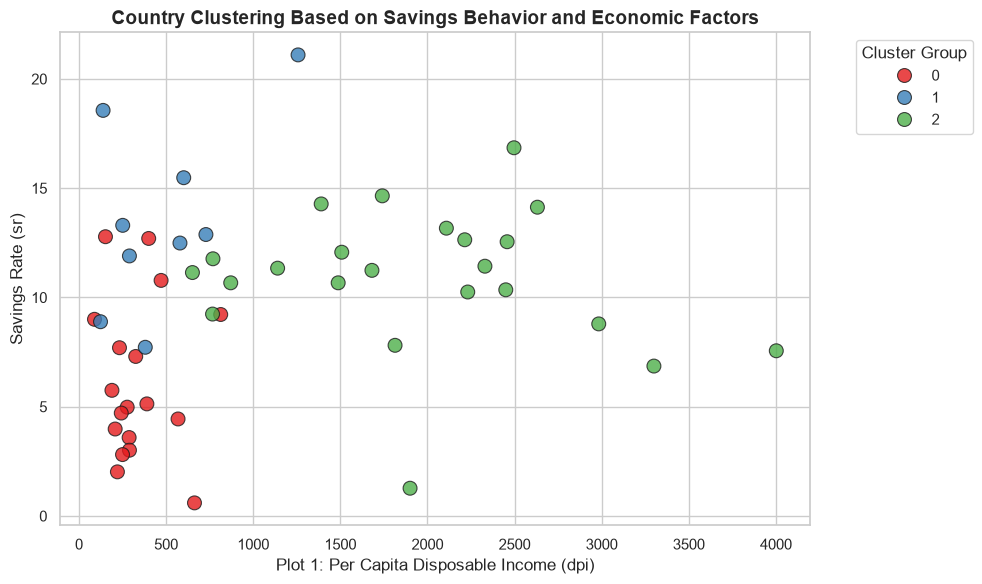

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset (assuming 'lifecyclesavings.csv' is in your working directory)
df = pd.read_csv("lifecyclesavings.csv")

# 2. Prepare the feature set for clustering
# Savings behavior is primarily captured by 'sr' (savings rate),
# but can be influenced by demographic and economic factors like pop15, pop75, dpi, and ddpi.
# We select these numerical columns for clustering.
features = ["sr", "pop15", "pop75", "dpi", "ddpi"]
X = df[features]

# 3. Standardize the features
# K-Means is sensitive to the scale of variables (e.g., dpi is in thousands, sr is in single digits).
# StandardScaler ensures each feature contributes equally to the distance metric.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Apply K-Means Clustering
# We choose 3 clusters to group countries into distinct savings/economic profiles.
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# 5. Visualize the result using a labeled Seaborn scatter plot
# We plot Savings Rate ('sr') against Disposable Income ('dpi'), colored by cluster group.
plt.figure(figsize=(10, 6))

# Set Seaborn styling
sns.set_theme(style="whitegrid")

# Create a scatter plot with country names or markers
scatter_plot = sns.scatterplot(
    data=df,
    x="dpi",
    y="sr",
    hue="Cluster",
    palette="Set1",
    s=100,
    alpha=0.8,
    edgecolor="k",
)

# 6. Add labels and title for clarity
plt.title(
    "Country Clustering Based on Savings Behavior and Economic Factors",
    fontsize=14,
    weight="bold",
)
plt.xlabel("Plot 1: Per Capita Disposable Income (dpi)", fontsize=12)
plt.ylabel("Savings Rate (sr)", fontsize=12)
plt.legend(title="Cluster Group", bbox_to_anchor=(1.05, 1), loc="upper left")

# Optionally, annotate a few points or display the plot
plt.tight_layout()
plt.show()

In [9]:
#Verfication step: shape
df.shape

(50, 7)

In [10]:
#Verfication step, calculate mean of each column.
df.describe()

,sr,pop15,pop75,dpi,ddpi,Cluster
count,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000
mean,9.671000,35.089600,2.293000,1106.758400,3.757600,1.100000
std,4.480407,9.151727,1.290771,990.868889,2.869871,0.909137
min,0.600000,21.440000,0.560000,88.940000,0.220000,0.000000
25%,6.970000,26.215000,1.125000,288.207500,2.002500,0.000000
50%,10.510000,32.575000,2.175000,695.665000,3.000000,1.000000
75%,12.617500,44.065000,3.325000,1795.622500,4.477500,2.000000
max,21.100000,47.640000,4.700000,4001.890000,16.710000,2.000000


The AI program added a column, 'Cluster', and assigned the group number 0,1,2. The final plot does not show 3 distinctive groups in my opinion. 

In [11]:
#Count the Number of countries in each Cluster
df['Cluster'].value_counts()

Cluster
2    23
0    18
1     9
Name: count, dtype: int64

In [12]:
cluster_1_countries = df[df["Cluster"] == 1][["Contry", "Cluster"]]
print(cluster_1_countries)

            Contry  Cluster
4           Brazil        1
7            China        1
22           Japan        1
25           Malta        1
34        Portugal        1
36  South Rhodesia        1
45          Zambia        1
46         Jamaica        1
48           Libya        1


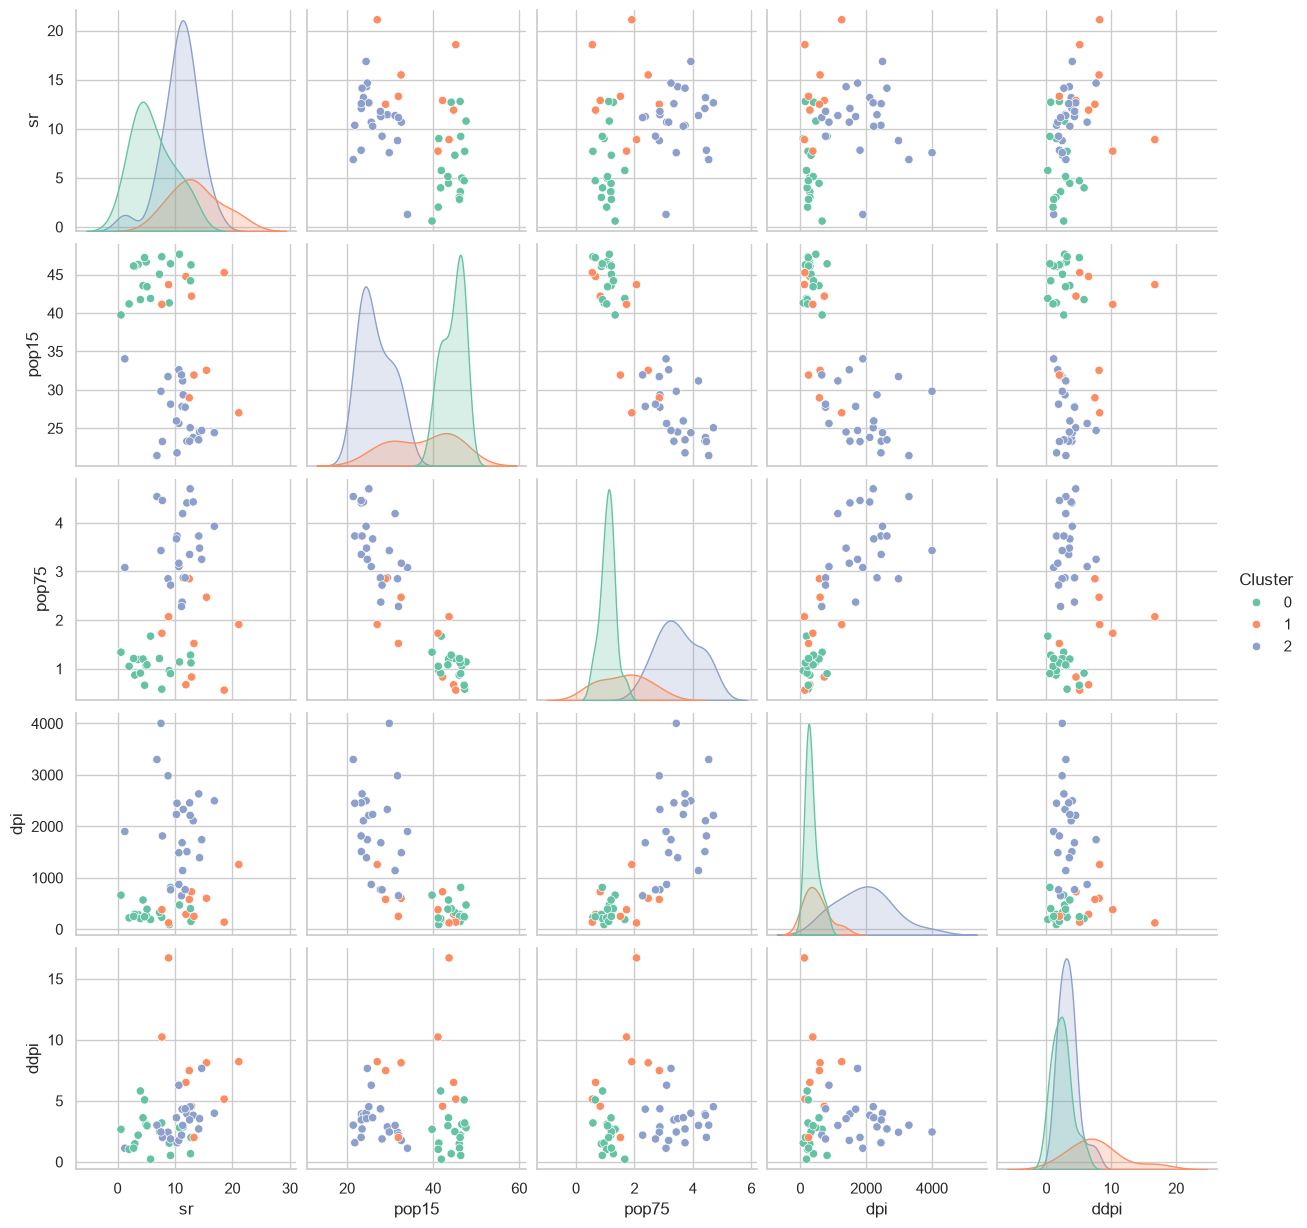

In [13]:
# I'd like to view the graphs to see how everything impacts cluster.
# Pairplot colored by cluster, showing relationships across all numeric features
sns.pairplot(df.dropna(), hue='Cluster', palette='Set2', diag_kind='kde')
plt.show()

# New AI prompt
Prompt: This cluster grouping is not obvious to me visually. Is there another presentation that shows the clustering more clearly?

Explanation: When K-Means clustering is performed on features with different underlying distributions (like dpi spanning into the thousands and sr in single digits), even after standardization, a 2D scatter plot like dpi vs sr can sometimes make the clusters look overlapping or muddy because you're only looking at 2 dimensions out of 5.

Here are three alternative presentation approaches that can make the cluster separation much clearer:

# Change: I picked #1 becuase I did not understand #2 and #3

1. Dimensionality Reduction via PCA (Principal Component Analysis)
Instead of plotting just two original features (dpi vs sr), PCA compresses all 5 features (sr, pop15, pop75, dpi, ddpi) into 2 principal components that capture the maximum possible variance of the data. This often reveals a much cleaner, wider separation between groups.

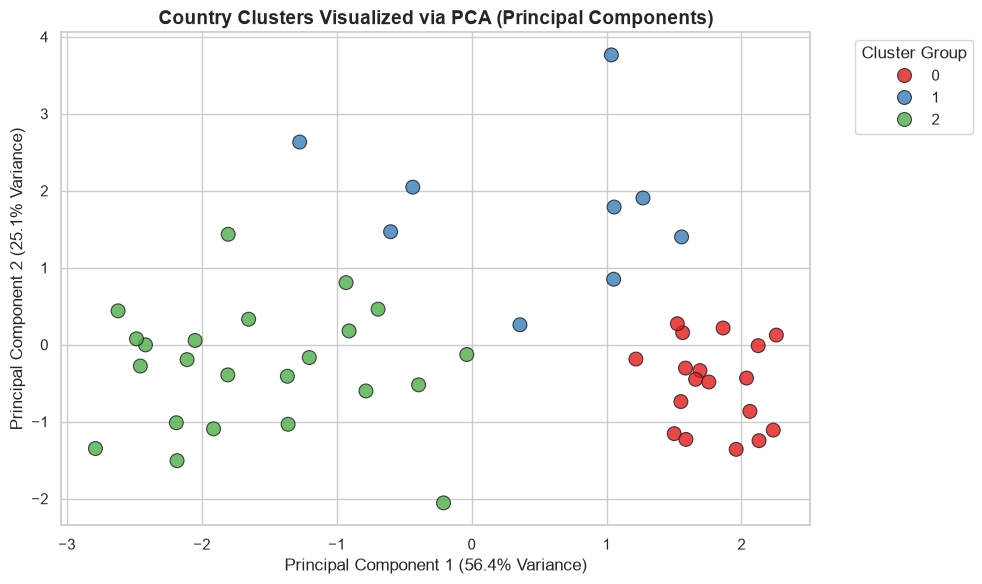

In [14]:
# New code
from sklearn.decomposition import PCA

# Reduce the 5 scaled features down to 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Add principal components to the dataframe
df["PC1"] = X_pca[:, 0]
df["PC2"] = X_pca[:, 1]

# Plot the clusters in PCA space
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")
sns.scatterplot(
    data=df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    s=100,
    alpha=0.8,
    edgecolor="k",
)

plt.title(
    "Country Clusters Visualized via PCA (Principal Components)",
    fontsize=14,
    weight="bold",
)
plt.xlabel(
    f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)",
    fontsize=12,
)
plt.ylabel(
    f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)",
    fontsize=12,
)
plt.legend(title="Cluster Group", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [15]:
df.shape

(50, 9)

In [16]:
df.head()

,Contry,sr,pop15,pop75,dpi,ddpi,Cluster,PC1,PC2
0,Australia,11.43,29.35,2.87,2329.68,2.87,2,-1.365290,-0.410149
1,Austria,12.07,23.32,4.41,1507.99,3.93,2,-2.049022,0.054519
2,Belgium,13.17,23.80,4.43,2108.47,3.82,2,-2.416945,-0.002233
3,Bolivia,5.75,41.89,1.67,189.13,0.22,0,1.501810,-1.155836
4,Brazil,12.88,42.19,0.83,728.47,4.56,1,1.053062,0.850125


This looks like two clear clusters to me but I do not understand the coding and 

In [17]:
df.describe()

,sr,pop15,pop75,dpi,ddpi,Cluster,PC1,PC2
count,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,5.000000e+01,5.000000e+01
mean,9.671000,35.089600,2.293000,1106.758400,3.757600,1.100000,2.664535e-17,4.718448e-18
std,4.480407,9.151727,1.290771,990.868889,2.869871,0.909137,1.696959e+00,1.132122e+00
min,0.600000,21.440000,0.560000,88.940000,0.220000,0.000000,-2.787708e+00,-2.054868e+00
25%,6.970000,26.215000,1.125000,288.207500,2.002500,0.000000,-1.580529e+00,-7.046956e-01
50%,10.510000,32.575000,2.175000,695.665000,3.000000,1.000000,-1.216156e-01,-1.769445e-01
75%,12.617500,44.065000,3.325000,1795.622500,4.477500,2.000000,1.580267e+00,3.159731e-01
max,21.100000,47.640000,4.700000,4001.890000,16.710000,2.000000,2.258755e+00,3.764193e+00


Two new columns were added to the database. The calculated means for each column are still the same as the original database.

In [18]:
#Count the Number of countries in each Cluster
df['Cluster'].value_counts()

Cluster
2    23
0    18
1     9
Name: count, dtype: int64

In [19]:
#Prepare table of cluster sorted Countries
sorted_df = df.sort_values(by=['Cluster', 'Contry'])
title = "Life Cycle Savings Data by Cluster and Country"
print(sorted_df)

            Contry     sr  pop15  pop75      dpi   ddpi  Cluster       PC1  \
3          Bolivia   5.75  41.89   1.67   189.13   0.22        0  1.501810   
6            Chile   0.60  39.74   1.34   662.86   2.67        0  1.588625   
8         Colombia   4.98  46.64   1.06   276.65   3.08        0  2.038151   
9       Costa Rica  10.78  47.64   1.14   471.24   2.80        0  1.564550   
11         Ecuador   3.59  46.31   1.19   287.77   2.19        0  2.063059   
16       Guatamala   3.01  46.05   0.87   289.71   1.48        0  2.235817   
17        Honduras   7.70  47.32   0.58   232.44   3.19        0  2.124019   
19           India   9.00  41.31   0.96    88.94   1.54        0  1.585506   
23           Korea   3.98  41.74   0.91   207.68   5.81        0  1.864558   
49        Malaysia   4.71  47.20   0.66   242.69   5.08        0  2.258755   
29       Nicaragua   7.30  45.04   1.21   325.54   2.48        0  1.692640   
30          Panama   4.44  43.56   1.20   568.56   3.61        0

# Cluster Results for Life Cycle Savings Data
Using the data from the lifecyclesavings.csv cycle. I asked Gemini to write a cluster algorothm to idenitfy similar countries. The initial clustering did not stand out to me as 3 distinct groups so I asked Gemini to create another presentation that shows the clustering more clearly? Both scatter lots are shown above in addition to a table organized by cluster groups. There are 18 countries in Cluster 0, 9 in Cluster 1, and 23 in Cluster 2.

The database was verified before and after the AI code was pasted in. AI added three new columns; Cluster, PC1, PC2. Otherwise the database is unchanged as confirmed by shape and the calculation of mean for all columns.

The data from Plot #1 (which is the one I can understand), indicate that the lower the disposable income, the lower the savings ratio. This group is idenitfied as Cluster 0 (red). In general, higher the disposable income, the higher the savings ratio (Cluster 3, green). However, this is not linear, the savings ration does seem to flatten even as disposable incomes increase.

https://github.com/acamend/cs82a-portfolio